# 3E. Autoencoder - NSL-KDD Network Intrusion Detection
Dense autoencoder on NSL-KDD. Train on normal traffic, flag high reconstruction error as attack.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score, classification_report

In [2]:
cols = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
    "root_shell","su_attempted","num_root","num_file_creations","num_shells",
    "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
    "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
    "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
    "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
    "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
    "label","difficulty"]

train = pd.read_csv("../datasets/AutoEncoder/NSL-KDD/KDDTrain+.txt", header=None, names=cols)
test = pd.read_csv("../datasets/AutoEncoder/NSL-KDD/KDDTest+.txt", header=None, names=cols)
print(train.shape, test.shape)

(125973, 43) (22544, 43)


In [3]:
y_train = (train["label"] != "normal").astype(int).to_numpy()
y_test = (test["label"] != "normal").astype(int).to_numpy()

df = pd.concat([train.drop(columns=["label","difficulty"]),
                test.drop(columns=["label","difficulty"])], ignore_index=True)
df = pd.get_dummies(df, columns=["protocol_type","service","flag"], dtype="float32")

x = MinMaxScaler().fit_transform(df.to_numpy()).astype("float32")
x_train, x_test = x[:len(train)], x[len(train):]
x_train_norm = x_train[y_train == 0]
print("features:", x.shape[1], "train normal:", x_train_norm.shape, "test attacks:", y_test.sum())

features: 122 train normal: (67343, 122) test attacks: 12833


In [4]:
dim = x.shape[1]
model = keras.Sequential([
    layers.Input(shape=(dim,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(dim),
])
model.compile(optimizer="adam", loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         7,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 122)            │         7,930 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,066 (82.29 KB)

 Trainable params: 21,066 (82.29 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(x_train_norm, x_train_norm, epochs=20, batch_size=256, validation_split=0.1)

Epoch 1/20


  1/237 ━━━━━━━━━━━━━━━━━━━━ 3:17 838ms/step - loss: 0.0598

 50/237 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0334    

105/237 ━━━━━━━━━━━━━━━━━━━━ 0s 970us/step - loss: 0.0216

165/237 ━━━━━━━━━━━━━━━━━━━━ 0s 925us/step - loss: 0.0162

225/237 ━━━━━━━━━━━━━━━━━━━━ 0s 901us/step - loss: 0.0132

... (111 outputs left out)

 61/237 ━━━━━━━━━━━━━━━━━━━━ 0s 839us/step - loss: 3.5927e-04

121/237 ━━━━━━━━━━━━━━━━━━━━ 0s 838us/step - loss: 3.6003e-04

182/237 ━━━━━━━━━━━━━━━━━━━━ 0s 833us/step - loss: 3.6349e-04

237/237 ━━━━━━━━━━━━━━━━━━━━ 0s 969us/step - loss: 3.6466e-04 - val_loss: 3.8880e-04


In [6]:
recon = model.predict(x_test, batch_size=512)
err = np.mean((x_test - recon) ** 2, axis=1)

auc = roc_auc_score(y_test, err)
threshold = np.quantile(err[y_test == 0], 0.95)
y_pred = (err > threshold).astype(int)

print(f"AUC: {auc:.4f}")
print(classification_report(y_test, y_pred, target_names=["normal", "attack"]))

 1/45 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step

45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 


AUC: 0.9485
              precision    recall  f1-score   support

      normal       0.63      0.95      0.76      9711
      attack       0.94      0.58      0.72     12833

    accuracy                           0.74     22544
   macro avg       0.79      0.77      0.74     22544
weighted avg       0.81      0.74      0.74     22544



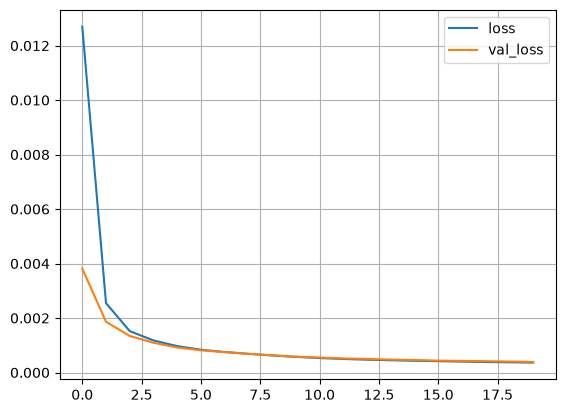

In [7]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()